In [ ]:
%pip install -q -U kaggle

In [ ]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle credentials loaded.")

Kaggle credentials loaded.


In [ ]:
%pip install -q -U kaggle

In [ ]:
!kaggle datasets download \
    -d arnavr10880/concrete-crack-images-for-classification \
    -p /content

Dataset URL: https://www.kaggle.com/datasets/arnavr10880/concrete-crack-images-for-classification
License(s): Attribution 4.0 International (CC BY 4.0)
100% 233M/233M [00:01<00:00, 134MB/s]



In [ ]:
import os
import zipfile
from pathlib import Path

zip_path = "/content/concrete-crack-images-for-classification.zip"
extract_path = "/content/concrete_defects"

if not os.path.exists(zip_path):
    print("ZIP file not found. Check the download output.")
else:
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

    print("Extraction complete!")

    for root, dirs, files in os.walk(extract_path):
        dirs.sort()
        images = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        if images:
            print(f"{root}: {len(images)} images")

Extraction complete!
/content/concrete_defects/Negative: 20000 images
/content/concrete_defects/Positive: 20000 images


In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

DATA_DIR = Path("/content/concrete_defects")

negative_paths = sorted((DATA_DIR / "Negative").glob("*"))
positive_paths = sorted((DATA_DIR / "Positive").glob("*"))

negative_paths = [p for p in negative_paths if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
positive_paths = [p for p in positive_paths if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]

print("Negative images:", len(negative_paths))
print("Positive images:", len(positive_paths))

# Use 4,000 images per class initially for faster development
negative_paths = negative_paths[:4000]
positive_paths = positive_paths[:4000]

all_paths = [str(p) for p in negative_paths + positive_paths]
all_labels = [0] * len(negative_paths) + [1] * len(positive_paths)

# 70% train, 30% temporary holdout
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

# Split the remaining 30% equally: 15% validation, 15% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("\nSplit sizes:")
print("Train:", len(train_paths), Counter(train_labels))
print("Validation:", len(val_paths), Counter(val_labels))
print("Test:", len(test_paths), Counter(test_labels))

Negative images: 20000
Positive images: 20000

Split sizes:
Train: 5600 Counter({1: 2800, 0: 2800})
Validation: 1200 Counter({1: 600, 0: 600})
Test: 1200 Counter({1: 600, 0: 600})


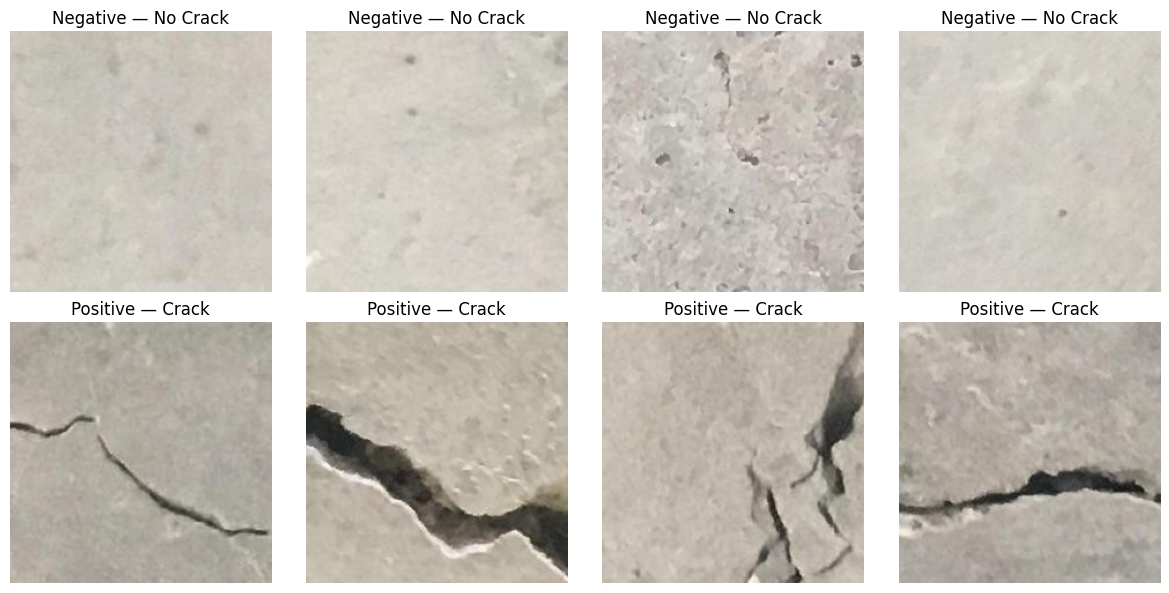

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate([0, 1]):
    paths = [
        p for p, y in zip(train_paths, train_labels)
        if y == label
    ]

    for col in range(4):
        img = Image.open(random.choice(paths)).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        axes[row, col].set_title(
            "Negative — No Crack" if label == 0 else "Positive — Crack"
        )

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ConcreteDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = ConcreteDataset(
    train_paths, train_labels, train_transform
)
val_dataset = ConcreteDataset(
    val_paths, val_labels, eval_transform
)
test_dataset = ConcreteDataset(
    test_paths, test_labels, eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

images, labels = next(iter(train_loader))
print("Device:", device)
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Device: cpu
Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])


In [ ]:
class DefectCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = DefectCNN().to(device)

print("CNN created successfully.")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

with torch.no_grad():
    output = model(torch.randn(2, 3, 128, 128).to(device))

print("Output shape:", output.shape)

CNN created successfully.
Trainable parameters: 389890
Output shape: torch.Size([2, 2])


In [ ]:
import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 4
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss /= train_total
    val_loss /= val_total
    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_model_state)
torch.save(model.state_dict(), "/content/concrete_baseline.pth")
print("Baseline model saved.")

Epoch 1/4 | Train Loss: 0.0798 | Train Acc: 0.9788 | Val Loss: 0.0445 | Val Acc: 0.9875
Epoch 2/4 | Train Loss: 0.0305 | Train Acc: 0.9918 | Val Loss: 0.0223 | Val Acc: 0.9933
Epoch 3/4 | Train Loss: 0.0254 | Train Acc: 0.9936 | Val Loss: 0.0533 | Val Acc: 0.9800
Epoch 4/4 | Train Loss: 0.0317 | Train Acc: 0.9902 | Val Loss: 0.0745 | Val Acc: 0.9917
Baseline model saved.


In [11]:
from collections import Counter
import random

random.seed(42)

# Separate training samples by class
negative_samples = [
    (p, y) for p, y in zip(train_paths, train_labels) if y == 0
]
positive_samples = [
    (p, y) for p, y in zip(train_paths, train_labels) if y == 1
]

# Keep all negative samples, but only 20% of positive samples
positive_reduced = random.sample(
    positive_samples,
    int(0.20 * len(positive_samples))
)

imbalanced_samples = negative_samples + positive_reduced
random.shuffle(imbalanced_samples)

imbalanced_paths = [p for p, y in imbalanced_samples]
imbalanced_labels = [y for p, y in imbalanced_samples]

print("Imbalanced training distribution:")
print(Counter(imbalanced_labels))
print("Total training images:", len(imbalanced_labels))

Imbalanced training distribution:
Counter({0: 2800, 1: 560})
Total training images: 3360


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy
from torch.utils.data import DataLoader

imbalanced_dataset = ConcreteDataset(
    imbalanced_paths,
    imbalanced_labels,
    train_transform
)

imbalanced_loader = DataLoader(
    imbalanced_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

counts = Counter(imbalanced_labels)

class_weights = torch.tensor(
    [
        len(imbalanced_labels) / (2 * counts[0]),
        len(imbalanced_labels) / (2 * counts[1])
    ],
    dtype=torch.float32,
    device=device
)

print("Class weights:", class_weights)

weighted_model = DefectCNN().to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(weighted_model.parameters(), lr=0.001)

EPOCHS = 4
best_weighted_loss = float("inf")
best_weighted_state = copy.deepcopy(weighted_model.state_dict())

for epoch in range(EPOCHS):
    weighted_model.train()
    train_loss = 0.0

    for images, labels in imbalanced_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = weighted_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

    weighted_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = weighted_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss / len(imbalanced_dataset):.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    if val_loss < best_weighted_loss:
        best_weighted_loss = val_loss
        best_weighted_state = copy.deepcopy(weighted_model.state_dict())

weighted_model.load_state_dict(best_weighted_state)
torch.save(
    weighted_model.state_dict(),
    "/content/concrete_weighted.pth"
)

print("Weighted-loss model saved.")

Class weights: tensor([0.6000, 3.0000])
Epoch 1/4 | Train Loss: 0.1871 | Val Loss: 0.0380 | Val Accuracy: 0.9892
Epoch 2/4 | Train Loss: 0.0848 | Val Loss: 0.0373 | Val Accuracy: 0.9883
Epoch 3/4 | Train Loss: 0.0554 | Val Loss: 0.1188 | Val Accuracy: 0.9750
Epoch 4/4 | Train Loss: 0.0449 | Val Loss: 0.0230 | Val Accuracy: 0.9908
Weighted-loss model saved.


In [13]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score,
    classification_report
)

def evaluate_defect_model(model, loader, name):
    model.eval()

    y_true, y_pred, y_prob = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(outputs.argmax(dim=1).cpu().numpy())
            y_prob.extend(probs[:, 1].cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Crack Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Crack Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Crack F1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "Average Precision": average_precision_score(y_true, y_prob)
    }

    print(f"\n{name}")
    print(classification_report(
        y_true, y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))
    print("Confusion matrix:\n", cm)

    return results, y_true, y_prob

# Restore the best unweighted baseline checkpoint
baseline_model = DefectCNN().to(device)
baseline_model.load_state_dict(
    torch.load(
        "/content/concrete_baseline.pth",
        map_location=device,
        weights_only=True
    )
)

weighted_model.load_state_dict(
    torch.load(
        "/content/concrete_weighted.pth",
        map_location=device,
        weights_only=True
    )
)

baseline_results, y_true, baseline_prob = evaluate_defect_model(
    baseline_model, test_loader, "Unweighted baseline"
)

weighted_results, _, weighted_prob = evaluate_defect_model(
    weighted_model, test_loader, "Weighted loss"
)

comparison = pd.DataFrame([baseline_results, weighted_results])
display(comparison.round(4))


Unweighted baseline
              precision    recall  f1-score   support

    Negative       0.99      1.00      1.00       600
    Positive       1.00      0.99      1.00       600

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200

Confusion matrix:
 [[599   1]
 [  4 596]]

Weighted loss
              precision    recall  f1-score   support

    Negative       1.00      0.99      0.99       600
    Positive       0.99      1.00      0.99       600

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200

Confusion matrix:
 [[593   7]
 [  2 598]]


,Model,Accuracy,Crack Precision,Crack Recall,Crack F1,Specificity,Average Precision
0,Unweighted baseline,0.9958,0.9983,0.9933,0.9958,0.9983,0.9999
1,Weighted loss,0.9925,0.9884,0.9967,0.9925,0.9883,0.9995


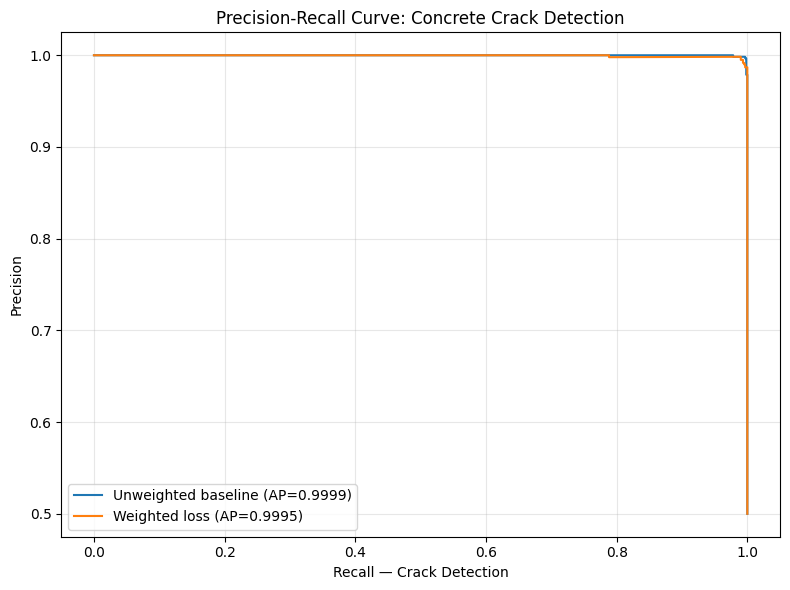

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Unweighted baseline", baseline_prob),
    ("Weighted loss", weighted_prob)
]:
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )
    ap = average_precision_score(y_true, probabilities)

    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")

plt.xlabel("Recall — Crack Detection")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Concrete Crack Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [16]:
import os
import shutil
import pandas as pd

save_dir = "/content/drive/MyDrive/Mini_Project_3_Results"
os.makedirs(save_dir, exist_ok=True)

# Save trained models
for filename in [
    "concrete_baseline.pth",
    "concrete_weighted.pth"
]:
    source = f"/content/{filename}"
    if os.path.exists(source):
        shutil.copy2(source, save_dir)
        print("Saved:", filename)

# Save comparison table
comparison.to_csv(
    os.path.join(save_dir, "model_comparison.csv"),
    index=False
)

print("Results saved to:", save_dir)

Saved: concrete_baseline.pth
Saved: concrete_weighted.pth
Results saved to: /content/drive/MyDrive/Mini_Project_3_Results


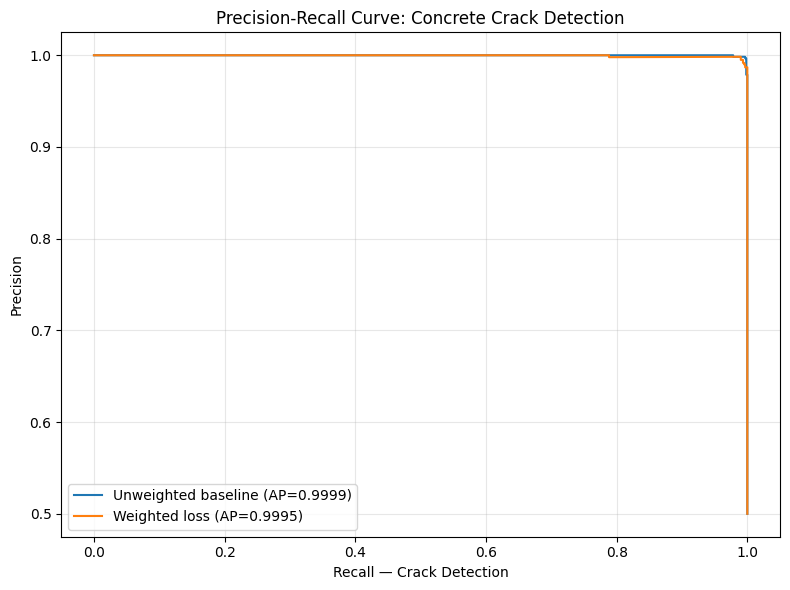

PR curve saved: /content/drive/MyDrive/Mini_Project_3_Results/precision_recall_curve.png


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Unweighted baseline", baseline_prob),
    ("Weighted loss", weighted_prob)
]:
    precision, recall, _ = precision_recall_curve(
        y_true, probabilities
    )
    ap = average_precision_score(y_true, probabilities)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")

plt.xlabel("Recall — Crack Detection")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: Concrete Crack Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plot_path = os.path.join(save_dir, "precision_recall_curve.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("PR curve saved:", plot_path)